# Fase 4 - Modelado
Búsqueda de hiperparámetros con CV agrupada (clásicos), búsqueda en validación (CNN y cabeza de especie) y selección con validación dejando una fuente fuera. Detalle en `docs/04_modelado.md`.

In [1]:
import os, sys, json
from pathlib import Path
while not Path('configs').exists(): os.chdir('..')
sys.path.insert(0, '.')
import pandas as pd
from IPython.display import SVG, Image, display
pd.set_option('display.width', 160)
T = Path('experiments/results/tables')

In [2]:
log = pd.read_csv(T / 'experiments_log.csv')
log[log['exp_id'].str.contains('_v2')][['exp_id', 'hyperparams', 'cv_f1_macro', 'val_f1_macro', 'val_recall_mala', 'fit_seconds']]

,exp_id,hyperparams,cv_f1_macro,val_f1_macro,val_recall_mala,fit_seconds
19,quality_majority_1126_v2,{},NaN,0.2241,0.0000,0.0
20,quality_logreg_1126_v2,"{""C"": 10}",0.7291,0.7330,0.8373,12.7
21,species_logreg_1126_v2,"{""C"": 10}",0.6973,0.8161,NaN,21.9
22,quality_svm_1126_v2,"{""C"": 100, ""gamma"": ""scale""}",0.8801,0.8829,0.9413,43.4
23,species_svm_1126_v2,"{""C"": 10, ""gamma"": ""scale""}",0.8110,0.9120,NaN,61.7
24,quality_rf_1126_v2,"{""max_depth"": null, ""min_samples_leaf"": 3, ""n_...",0.8494,0.8673,0.9166,100.4
25,species_rf_1126_v2,"{""max_depth"": 20, ""min_samples_leaf"": 3, ""n_es...",0.7687,0.8886,NaN,130.3
26,cnn_1126_v2,"{""input"": 64, ""filters"": [32, 64, 128], ""epoch...",NaN,0.7660,0.9372,1280.8
27,species_tl_1126_v21,"{""backbone"": ""MobileNetV2 ImageNet 128, congel...",NaN,0.9305,NaN,14.8
28,species_tl_1126_v22,"{""backbone"": ""MobileNetV2 ImageNet 128, congel...",NaN,0.9382,NaN,9.5


In [3]:
pd.read_csv(T / 'tuning_cnn.csv')

,config,lr,dropout,epochs,best_val_loss,val_f1_macro,val_recall_mala,val_cost,train_acc_q,val_acc_q,seconds
0,cnn_v4,0.002,0.3,30,0.5549,0.766,0.9372,0.3228,0.8469,0.8430,1280.8
1,cnn_lr1e3,0.001,0.3,30,0.5842,0.748,0.9423,0.3428,0.8253,0.8295,1064.6


In [4]:
pd.read_csv(T / 'tuning_cabeza_especie.csv').sort_values('val_accuracy', ascending=False)

,units,dropout,lr,val_accuracy,train_accuracy,val_loss,epochs
11,512,0.5,0.0003,0.9400,0.9984,0.2146,29.0
9,512,0.3,0.0003,0.9391,0.9999,0.2222,20.0
5,256,0.3,0.0003,0.9374,0.9985,0.1851,20.0
8,512,0.3,0.0010,0.9370,0.9939,0.2282,10.0
10,512,0.5,0.0010,0.9361,0.9921,0.2200,12.0
6,256,0.5,0.0010,0.9353,0.9919,0.2063,13.0
7,256,0.5,0.0003,0.9353,0.9955,0.1990,24.0
1,128,0.3,0.0003,0.9348,0.9959,0.1914,20.0
2,128,0.5,0.0010,0.9309,0.9943,0.2135,17.0
4,256,0.3,0.0010,0.9305,0.9955,0.2028,11.0


In [5]:
pd.read_csv(T / 'validacion_entre_fuentes.csv')

,tarea,candidato,kaggle,afruitdb,fruitvision,media
0,especie,svm,0.1801,0.5845,0.5421,0.4356
1,especie,rf,0.1916,0.6657,0.6752,0.5108
2,especie,logreg,0.1886,0.6121,0.4990,0.4332
3,especie,svm_c1,0.1791,0.5853,0.5905,0.4516
4,especie,emb_logreg,0.3538,0.8451,0.8001,0.6663
5,calidad,emb_head,0.6214,0.8767,0.7619,0.7534
6,calidad,svm,0.6564,0.7311,0.7364,0.7080
7,calidad,rf,0.7185,0.8093,0.8018,0.7765
8,especie,emb_head_cw,0.3365,0.8526,0.8525,0.6805
9,especie,emb_head,0.3363,0.8518,0.8484,0.6789


In [6]:
pd.read_csv(T / 'sobreajuste.csv')

,modelo,f1_train,f1_cv,f1_val,brecha_train_val
0,logreg,0.7511,0.7291,0.7330,0.0181
1,svm,0.9804,0.8801,0.8829,0.0974
2,rf,0.9863,0.8494,0.8673,0.1190


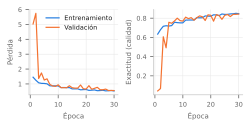

In [7]:
display(SVG(filename='report/figures/fig4_cnn_curvas.svg'))